# Web Search and Resarch Tools embedded if needed

In [69]:
from typing import Annotated, TypedDict
from dotenv import load_dotenv

from langgraph.graph import add_messages, StateGraph, MessagesState, START, END
from langchain_core.messages import AnyMessage, HumanMessage
from langgraph.graph.message import add_messages

from langchain_groq import ChatGroq

import arxiv
from langchain_community.tools import WikipediaQueryRun, ArxivQueryRun, DuckDuckGoSearchRun
from langchain_community.utilities import WikipediaAPIWrapper, ArxivAPIWrapper

from langgraph.checkpoint.memory import MemorySaver
from uuid import uuid4
import os

load_dotenv()

True

In [ ]:
# Tools
# Arxiv is an tool for Resarch paper
class HTTPSArxivClient(arxiv.Client):
    def _format_url(self, search, start, page_size):
        url = super()._format_url(search, start, page_size)
        return url.replace(
            "http://export.arxiv.org",
            "https://export.arxiv.org"
        )


client = HTTPSArxivClient()

class ArxivSearchAdapter:

    def __init__(self, *args, **kwargs):
        self.search = arxiv.Search(*args, **kwargs)

    def results(self):
        return client.results(self.search)

api_wrapper_arxiv = ArxivAPIWrapper(
    top_k_results=2,
    doc_content_chars_max=500
)

api_wrapper_arxiv.arxiv_search = ArxivSearchAdapter


# 4. Create tool
arxiv_tool = ArxivQueryRun(
    api_wrapper=api_wrapper_arxiv,
    description="Search research papers on Arxiv"
)


In [33]:
api_wrapper_wiki = WikipediaAPIWrapper(top_k_results=2,doc_content_chars_max=500)
wikipedia = WikipediaQueryRun(api_wrapper=api_wrapper_wiki, description="Seach on Wikipedia")   

In [49]:
duck_duck_go = DuckDuckGoSearchRun(
    name="web_search_on_Duck_Duck_Go",
    description="Search the web for current events, recent news, live scores, and real-time information."
    )

In [50]:
tools = [duck_duck_go, arxiv_tool, wikipedia]

In [51]:
os.environ['GROQ_API_KEY'] = os.getenv("GROQ_API_KEY")

In [52]:
model = ChatGroq(model="qwen/qwen3.8-27b", temperature=0.2)

In [53]:
llm_with_tools = model.bind_tools(tools=tools)

In [54]:
# llm_with_tools.invoke("What is the result of Indian Cricket team tour of New Zeland 2026?")
llm_with_tools.invoke("What is rescent news on AI?")

AIMessage(content="I'll search for recent news on AI for you.\n\n", additional_kwargs={'tool_calls': [{'id': 'n6d75sn56', 'function': {'arguments': '{"query":"recent AI news 2025"}', 'name': 'web_search_on_Duck_Duck_Go'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 52, 'prompt_tokens': 438, 'total_tokens': 490, 'completion_time': 0.147967637, 'completion_tokens_details': None, 'prompt_time': 0.03306893, 'prompt_tokens_details': None, 'queue_time': 0.060020149, 'total_time': 0.181036567}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1d8dc-5c84-7565-87dd-cc3d52609b45-0', tool_calls=[{'name': 'web_search_on_Duck_Duck_Go', 'args': {'query': 'recent AI news 2025'}, 'id': 'n6d75sn56', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 438, 'output_tokens': 52, 'total_tokens': 490})

In [ ]:
class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

In [60]:
def tools_calling_llm(state: State) -> State:
    return {"messages": [llm_with_tools.invoke(state['messages'])]}

In [61]:
from langgraph.prebuilt import ToolNode, tools_condition

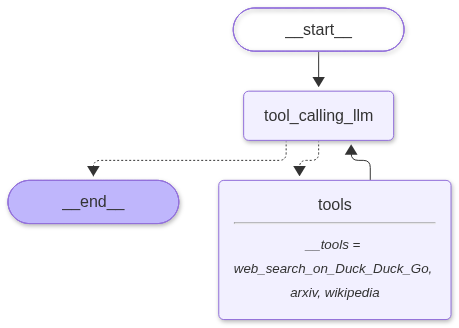

In [72]:
graph = StateGraph(State)

graph.add_node('tool_calling_llm', tools_calling_llm)
graph.add_node('tools', ToolNode(tools))


graph.set_entry_point('tool_calling_llm')
graph.add_conditional_edges('tool_calling_llm',tools_condition)
graph.add_edge('tools', 'tool_calling_llm')

build = graph.compile()
build

In [70]:
messages = build.invoke({'messages': HumanMessage("1706.03176")})

for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

1706.03176
================================== Ai Message ==================================
Tool Calls:
  arxiv (xw61ehz5z)
 Call ID: xw61ehz5z
  Args:
    query: 1706.03176
================================= Tool Message =================================
Name: arxiv

Published: 2017-06-10
Title: Swapping of Gaussian Einstein-Podolsky-Rosen steering
Authors: Meihong Wang, Zhongzhong Qin, Xiaolong Su
Summary: Einstein-Podolsky-Rosen (EPR) steering is a quantum mechanical phenomenon that allows one party to steer the state of a distant party by exploiting their shared entanglement. It has potential applications in secure quantum communication. In this paper, we present two swapping schemes of Gaussian EPR steering, single-channel and dual-channel schemes, by th
